# 05. 어떤 예측을 언제 쓸 것인가 — 의사결정 기간별 운영 규칙

**SCM 담당자에게 필요한 예측은 기간마다 다르다.**
- **1개월 앞**: 다음 달 입고 흐름을 보고 운영을 조정한다(긴급 항공 보충, 창고 인력).
- **3개월 앞**: 분기 물량과 해상·항공 운송 계획을 잡는다.

이 노트북은 가장 단순한 기준선에서 출발해 통계 모델, 계층 정합, 머신러닝 9종을 **같은 rolling-origin 조건**에서 비교하고, 기간별로 쓸 규칙을 정한다.

- 대상: 미국 측 해상+항공 수입 금액(전체의 98.6%), 품목군 4 × 운송수단 2의 15개 노드 계층. **공개 수입통계의 예측**이며, 기업 내부 판매·재고·발주 데이터를 쓰는 수요예측이 아니다. 발주 판단을 돕는 외부 시장 흐름 지표로 읽는다.
- 예측 기준 시점: 2025-12 ~ 2026-07(학습 24개월 이상), 1~3개월 앞. 모든 모델은 기준 시점 이후 값을 볼 수 없다(`tests/test_forecast.py`, `tests/test_ml.py`).
- 비교 기준: 구매 담당자가 흔히 쓰는 **'작년 같은 달'**(seasonal naive). 설계와 결과 요약은 [모델 카드](../reports/model_card.md).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from kbeauty import forecast, hierarchy, ml, report, warehouse
from kbeauty.paths import BACKTEST_FIRST_ORIGIN, POLICY_MONTH, REPO, TABLES_DIR
from kbeauty.viz import annotations as an
from kbeauty.viz import notebook as nbviz
from kbeauty.viz.theme import COLORS as C
from kbeauty.viz.forecasting import MODEL_KO

%matplotlib inline
nbviz.setup()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
fct = warehouse.load("fct_imports_hs10_mode_monthly")
bottom = hierarchy.bottom_series(fct)
nodes = hierarchy.all_nodes(bottom)
krw = warehouse.load("stg_fed_board__fx_monthly").query("currency == 'KRW'")
krw = krw.assign(month=pd.to_datetime(krw["month"])).set_index("month")["lcu_per_usd"]
FIRST = int(np.flatnonzero(bottom.index == pd.Timestamp(BACKTEST_FIRST_ORIGIN))[0])
print(nodes.shape, "| first origin", bottom.index[FIRST].date(), "| last month", bottom.index[-1].date())

(32, 15) | first origin 2025-12-01 | last month 2026-08-01


## 결론 먼저: 운영 규칙

| 의사결정 기간 | 사용할 예측 | 이유 | 근거 수준 |
|---|---|---|---|
| 1개월 앞 | **직전 값** | 합계 WAPE 0.112, 비교한 모델 중 가장 낮음. 순위는 통계적으로 확정되지 않음(DM p 0.17) | `ESTIMATED` |
| 3개월 앞 | **계절 ETS, 품목·운송수단별 합** | 합계 WAPE 0.160, '작년 같은 달' 대비 우위 DM p 0.001(n 6) | `ESTIMATED` |
| 머신러닝 | **보류** | 검증 성적으로 고른 모델이 직전 값과 통계적으로 구분되는 개선을 입증하지 못해 직전 값 기준선 유지(공식 기준 Linux 고정 환경 1개월 0.109 vs 0.112, DM p 0.91. 작성 환경 0.138은 진단 이력), 3개월 앞은 구분 불가 | `ESTIMATED`, 고정 예측 채점 대기 |
| 쓰지 않을 것 | '작년 같은 달' | 정책 이후 수준이 이동해 모든 수준·기간에서 하위권 | `ESTIMATED` |

아래는 이 규칙에 이른 근거다.

## 1. 예측 대상: 15개 노드 계층

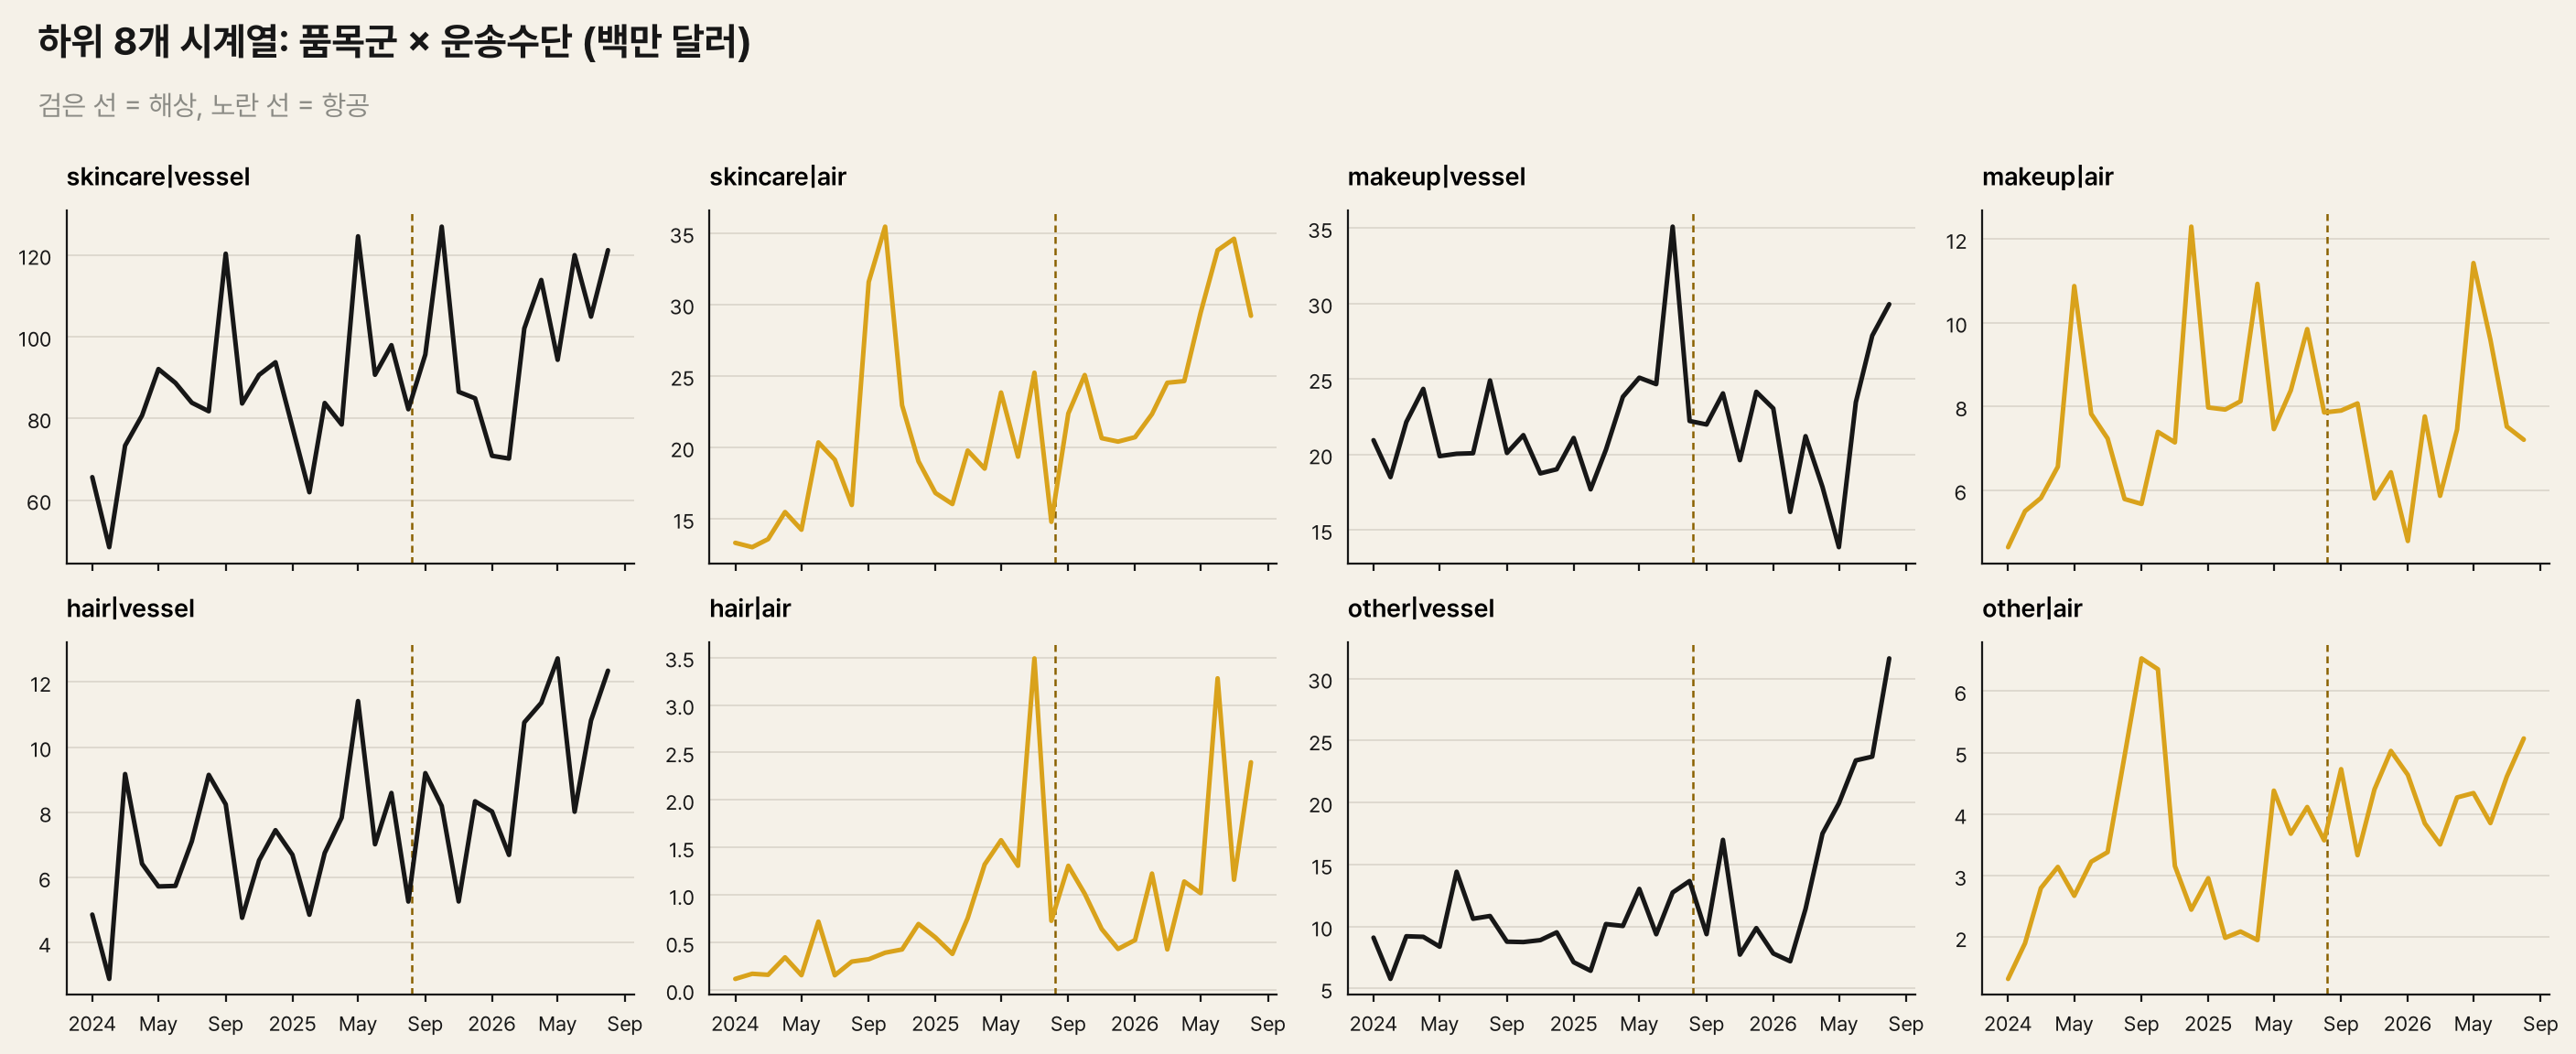

,total,all|vessel,all|air,skincare|all,makeup|all,hair|all,other|all,skincare|vessel,skincare|air,makeup|vessel,makeup|air,hair|vessel,hair|air,other|vessel,other|air
최근 12개월 비중,1.000,0.791,0.209,0.676,0.159,0.057,0.108,0.537,0.139,0.119,0.041,0.050,0.007,0.084,0.023


In [2]:
fig, axes = nbviz.figure((14, 6.2), 2, 4, title="하위 8개 시계열: 품목군 × 운송수단 (백만 달러)", subtitle="검은 선 = 해상, 노란 선 = 항공", sharex=True)
for ax, col in zip(axes.ravel(), bottom.columns):
    ax.plot(bottom.index, bottom[col] / 1e6, color=C["primary"] if col.endswith("air") else C["ink"], lw=1.8)
    an.policy_marker(ax, label=False)
    ax.set_title(col, fontsize=10); ax.tick_params(labelsize=8)
plt.show()
share = (nodes.iloc[-12:].sum() / nodes["total"].iloc[-12:].sum()).rename("최근 12개월 비중")
share.to_frame().T

**발견**: 최근 12개월 기준 해상 79.1%, 항공 20.9%. 품목군으로는 스킨케어 67.6%, 메이크업 15.9%, 기타 10.8%, 헤어 5.7%다.
가장 작은 노드는 헤어 항공(0.7%)이다. 작은 노드는 월별 변동이 커서 예측이 어렵고, 계층 정합에서도 문제가 생길 수 있다(3절).

## 2. 가장 단순한 기준선과 통계 모델

| 모델 | 설명 |
|---|---|
| naive | 직전 달 값 |
| seasonal_naive | 작년 같은 달 |
| seasonal_naive_growth | 작년 같은 달 × 최근 12개월 성장률 |
| ets_damped | 감쇠 추세 지수평활(로그) |
| ets_seasonal | 감쇠 추세 + 12개월 계절 지수평활(로그) |
| sarimax_fx_policy | SARIMAX(1,1,0) + 정책 후 더미 + 원/달러(미래 환율은 마지막 값 유지) |

각 노드의 예측은 독립적으로 만든 뒤(base), 상위·하위 합계가 맞도록 정합한다(bottom-up, OLS). 머신러닝 모델은 4절에서 따로 비교한다.

In [3]:
models = hierarchy.standard_models(POLICY_MONTH, krw)
bt = hierarchy.backtest(bottom, models, FIRST)
lw = hierarchy.level_wape(bt)
base = lw[lw.method == "base"].pivot_table(index="model", columns=["level", "horizon"], values="wape")
base[["total", "bottom"]].sort_values(("total", 1))

C:\Users\user\Documents\github\kbeauty-us-supply-chain\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


level                 total             bottom            
horizon                   1     2     3      1     2     3
model                                                     
naive                 0.112 0.147 0.196  0.173 0.205 0.245
sarimax_fx_policy     0.118 0.160 0.209  0.177 0.201 0.249
ets_seasonal          0.140 0.155 0.169  0.195 0.203 0.218
seasonal_naive_growth 0.162 0.162 0.174  0.242 0.247 0.268
seasonal_naive        0.187 0.205 0.213  0.259 0.271 0.283
ets_damped            0.193 0.198 0.193  0.212 0.224 0.234

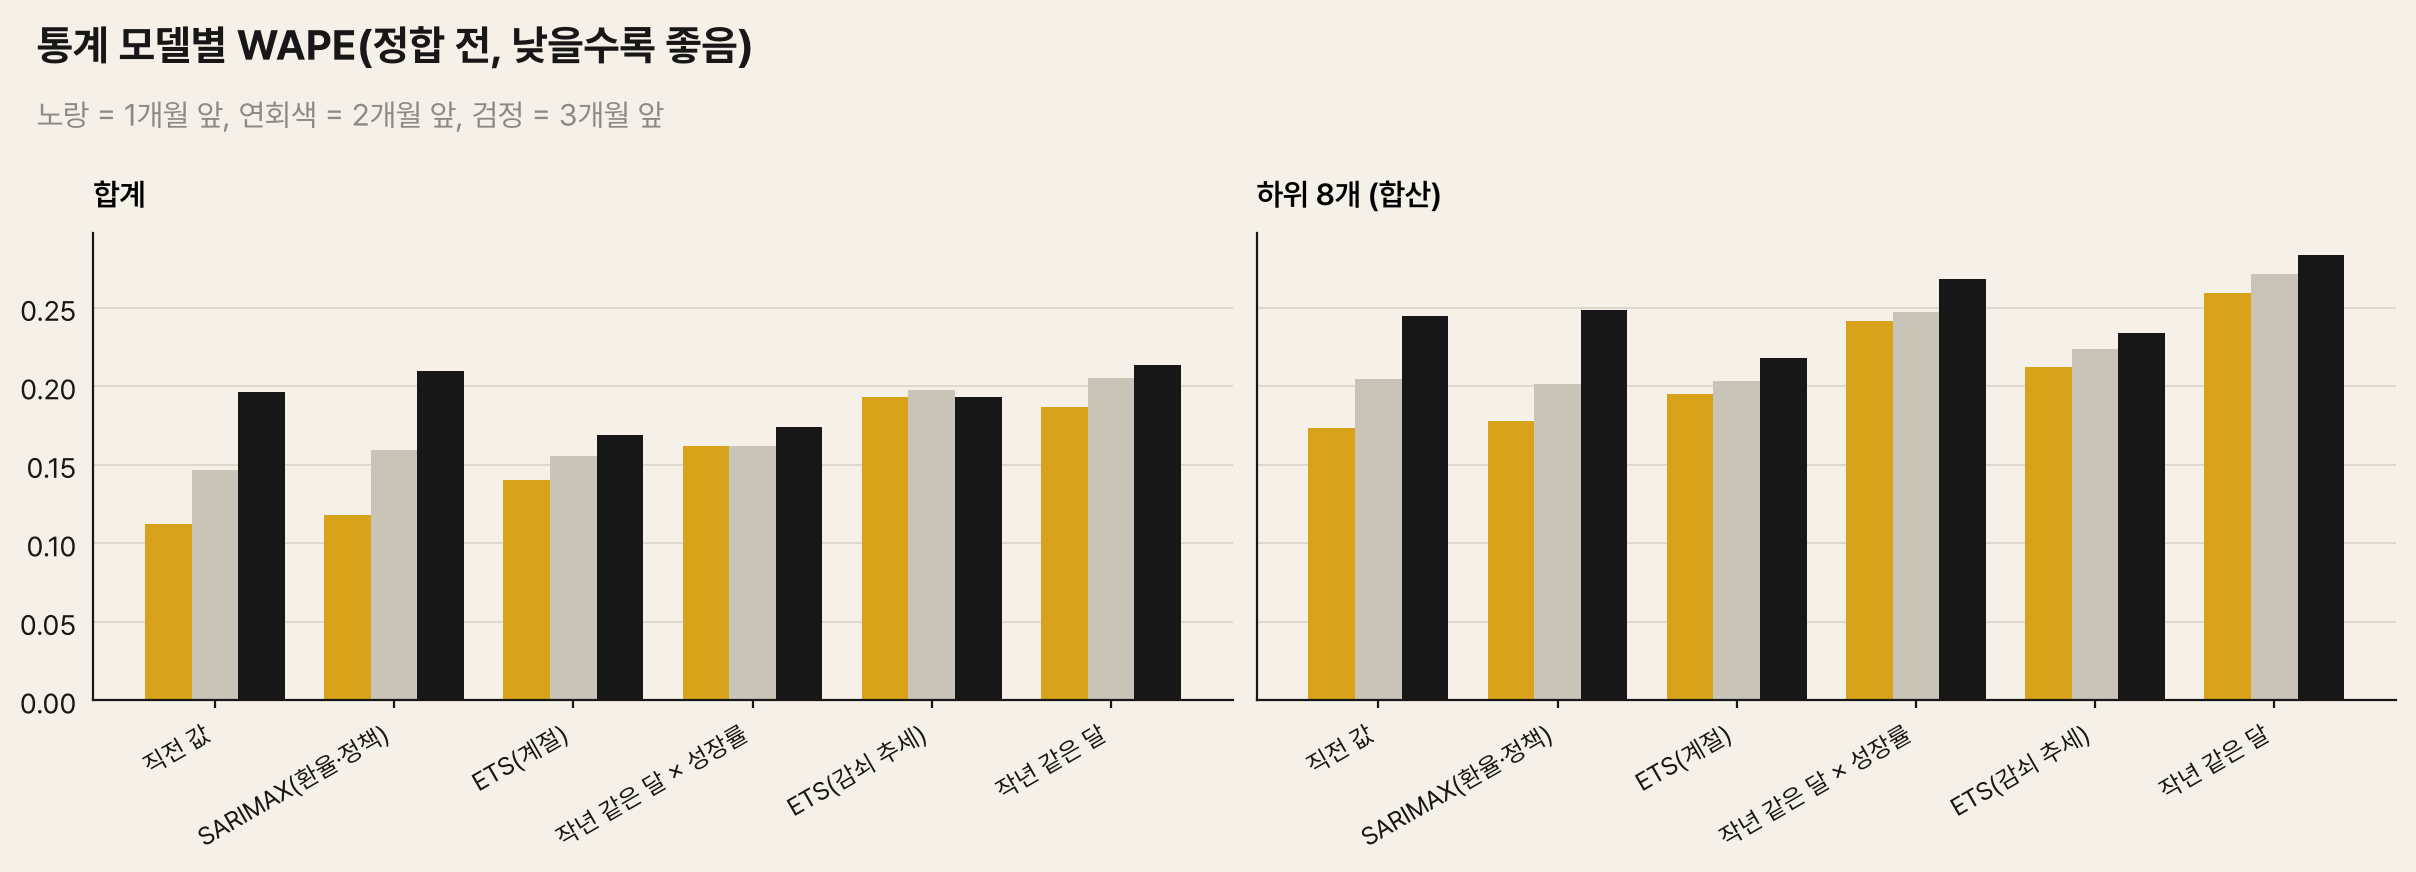

In [4]:
fig, axes = nbviz.figure((12, 4.8), 1, 2, title="통계 모델별 WAPE(정합 전, 낮을수록 좋음)", subtitle="노랑 = 1개월 앞, 연회색 = 2개월 앞, 검정 = 3개월 앞", sharey=True)
order = ["naive", "sarimax_fx_policy", "ets_seasonal", "seasonal_naive_growth", "ets_damped", "seasonal_naive"]
for ax, level in zip(axes, ["total", "bottom"]):
    d = lw[(lw.method == "base") & (lw.level == level)].pivot(index="model", columns="horizon", values="wape").reindex(order)
    for i, (h, c) in enumerate(((1, C["primary"]), (2, C["faint"]), (3, C["ink"]))):
        ax.bar(np.arange(len(order)) + (i - 1) * 0.26, d[h], width=0.26, color=c)
    ax.set_xticks(range(len(order)), [MODEL_KO[m] for m in order], rotation=30, ha="right", fontsize=9)
    ax.set_title("합계" if level == "total" else "하위 8개 (합산)")
plt.show()

**발견** (정합 전 base 예측의 WAPE, 낮을수록 좋음. 정합 후 결과는 3절, 머신러닝은 4절):

| 수준 | 1개월 앞 최선 | 2개월 앞 최선 | 3개월 앞 최선 | 작년 같은 달 (1/2/3개월) |
|---|---|---|---|---|
| 합계 | 직전 값 0.112 | 직전 값 0.147 | ETS(계절) 0.169 | 0.187 / 0.205 / 0.213 |
| 하위 8개 | 직전 값 0.173 | SARIMAX 0.201 | ETS(계절) 0.218 | 0.259 / 0.271 / 0.283 |

- **'작년 같은 달'은 모든 수준·시점에서 하위권**이다. 1년 전 패턴이 정책 이후 이동한 수준을 반영하지 못한다.
- **가까운 미래는 단순할수록 좋다.** 1개월 앞에서는 직전 값이 가장 정확하다. 환율과 정책 더미를 넣은 SARIMAX(0.118)도 직전 값을 이기지 못했다.
  설명 변수가 들어가도 짧은 기간에서는 추정 잡음이 더 크다.
- **먼 미래는 계절성을 다루는 모델이 낫다.** 3개월 앞에서는 계절 ETS가 합계와 하위 노드 모두에서 가장 좋았다.
- 감쇠 추세 ETS(계절 없음)는 계절성을 무시해 좋지 않았다.

## 3. 계층 정합: 합계가 맞게 고치면 정확도도 좋아지나

In [5]:
rec = lw[lw.model.isin(["ets_seasonal", "ets_damped", "sarimax_fx_policy", "naive"])].pivot_table(
    index=["model", "level"], columns=["method", "horizon"], values="wape")
rec.loc[(slice(None), ["total", "bottom"]), :]

method                    base             bottom_up               ols        \
horizon                      1     2     3         1     2     3     1     2   
model             level                                                        
ets_damped        total  0.193 0.198 0.193     0.174 0.195 0.196 0.187 0.196   
ets_seasonal      total  0.140 0.155 0.169     0.134 0.144 0.160 0.135 0.150   
naive             total  0.112 0.147 0.196     0.112 0.147 0.196 0.112 0.147   
sarimax_fx_policy total  0.118 0.160 0.209     0.119 0.161 0.212 0.118 0.160   
ets_damped        bottom 0.212 0.224 0.234     0.212 0.224 0.234 0.221 0.230   
ets_seasonal      bottom 0.195 0.203 0.218     0.195 0.203 0.218 0.203 0.218   
naive             bottom 0.173 0.205 0.245     0.173 0.205 0.245 0.173 0.205   
sarimax_fx_policy bottom 0.177 0.201 0.249     0.177 0.201 0.249 0.177 0.201   

method                          
horizon                      3  
model             level         
ets_damped        total  0.194  
ets_seasonal      total  0.165  
naive             total  0.196  
sarimax_fx_policy total  0.210  
ets_damped        bottom 0.232  
ets_seasonal      bottom 0.231  
naive             bottom 0.245  
sarimax_fx_policy bottom 0.248

**발견**:
- **bottom-up 정합은 ETS 합계 예측을 일관되게 개선**했다. 계절 ETS 0.140 → 0.134(1개월), 0.155 → 0.144(2개월), 0.169 → 0.160(3개월). 감쇠 ETS도 1개월에서 0.193 → 0.174.
  잡음이 서로 다른 하위 시계열을 따로 예측해 더하면, 합계를 직접 예측할 때보다 오차가 상쇄된다.
- **OLS 정합은 합계를 조금 개선하지만 하위 노드를 나쁘게 만든다**(계절 ETS 하위 0.195 → 0.203, 3개월 0.218 → 0.231).
  큰 노드의 오차를 작은 노드로 나눠 넘기기 때문이다. 3개월 앞에서는 가장 작은 노드(헤어 항공)에 **음수 예측이 1건** 생겼다.
- 직전 값 예측은 원래 합계가 맞으므로 정합해도 변하지 않는다.

**판단**: 운영에 쓴다면 **계절 ETS + bottom-up**이 합계와 하위 노드 모두에서 일관된 선택이다. OLS는 작은 노드가 많은 계층에서 음수 예측 위험이 있어 권하지 않는다.

## 4. 머신러닝 9종: 여러 모델을 같은 규칙으로 겨루고, 검증 성적으로 고른다

통계 모델은 시계열마다 따로 맞춘다. 머신러닝 모델은 하위 8개 시계열을 **한 모델로 함께 학습**(global model)해, 시계열 하나당 24~31개월뿐인 데이터 부족을 메울 수 있는지 본다.

| 계열 | 모델 | 조정한 하이퍼파라미터 |
|---|---|---|
| 선형 | Ridge, Elastic Net | 규제 강도 |
| 거리 기반 | kNN | 이웃 수 |
| 트리 앙상블 | Random Forest, Extra Trees | 잎 최소 표본 수 |
| 부스팅 | Gradient Boosting(scikit-learn), LightGBM, XGBoost | 트리 깊이·잎 수 |
| 신경망 | MLP(은닉층 16) | 가중치 규제 |

- **공통 특징**: 기준 시점의 최근 3개월 로그 값, 월, 시계열, 정책 후 여부, 기준 시점의 원/달러. 'full' 특징은 여기에 작년 같은 달을 더한다(대신 학습 행이 12개월 줄어든다).
- **함께 조정한 설계 선택**: 목표(로그 수준 또는 직전 달 대비 로그 변화. 트리는 학습 범위 밖 수준을 외삽하지 못한다)와 특징 묶음(short·full). 모델 9종 × 설정 2~3개 × 목표 2 × 특징 2 = **76개 설정**.
- **선택 규칙(시험 달을 보지 않는다)**: 각 기준 시점에서, 그 시점에 이미 관측된 **마지막 3개월**을 검증 구간으로 삼아 76개 설정을 채점한다(검증 달 v는 v − h 이전 자료로만 학습). 모델마다 가장 좋은 설정으로 기준 시점까지 다시 학습해 예측하고(`ml_<모델>`), 전체에서 가장 좋은 설정을 `ml_selected`로 둔다. `ml_selected`가 "여러 모델을 비교해 가장 좋은 것을 고른다"는 절차의 정직한 표본 외 성적이다.
- 하위 8개 예측을 더해 15개 노드 전체를 만든다(bottom-up). 모든 학습은 단일 스레드·고정 시드라 다시 실행해도 같은 숫자가 나온다(`tests/test_ml.py`).

In [6]:
mlr = ml.backtest(bottom, krw, FIRST, POLICY_MONTH)   # 약 3~4분
all_bt = pd.concat([bt, mlr.forecasts], ignore_index=True)
lw_all = hierarchy.level_wape(all_bt)
ref = [("naive", "base"), ("ets_seasonal", "bottom_up"), ("sarimax_fx_policy", "base")]
ml_rows = [(m, "bottom_up") for m in sorted(mlr.forecasts.model.unique())]
cmp = lw_all.set_index(["model", "method"]).loc[ref + ml_rows].reset_index()
cmp.pivot_table(index=["model", "method"], columns=["level", "horizon"], values="wape")[["total", "bottom"]].sort_values(("total", 1))

level                          total             bottom            
horizon                            1     2     3      1     2     3
model                method                                        
ml_lightgbm          bottom_up 0.082 0.090 0.172  0.161 0.181 0.221
ml_xgboost           bottom_up 0.093 0.094 0.153  0.159 0.181 0.214
ml_gradient_boosting bottom_up 0.103 0.084 0.186  0.168 0.167 0.230
naive                base      0.112 0.147 0.196  0.173 0.205 0.245
sarimax_fx_policy    base      0.118 0.160 0.209  0.177 0.201 0.249
ml_elastic_net       bottom_up 0.132 0.140 0.140  0.185 0.185 0.208
ml_ridge             bottom_up 0.132 0.136 0.152  0.193 0.189 0.220
ets_seasonal         bottom_up 0.134 0.144 0.160  0.195 0.203 0.218
ml_selected          bottom_up 0.138 0.110 0.144  0.191 0.204 0.220
ml_knn               bottom_up 0.145 0.193 0.224  0.205 0.241 0.258
ml_mlp               bottom_up 0.147 0.151 0.214  0.219 0.243 0.264
ml_random_forest     bottom_up 0.157 0.144 0.149  0.214 0.202 0.209
ml_extra_trees       bottom_up 0.172 0.175 0.200  0.222 0.220 0.234

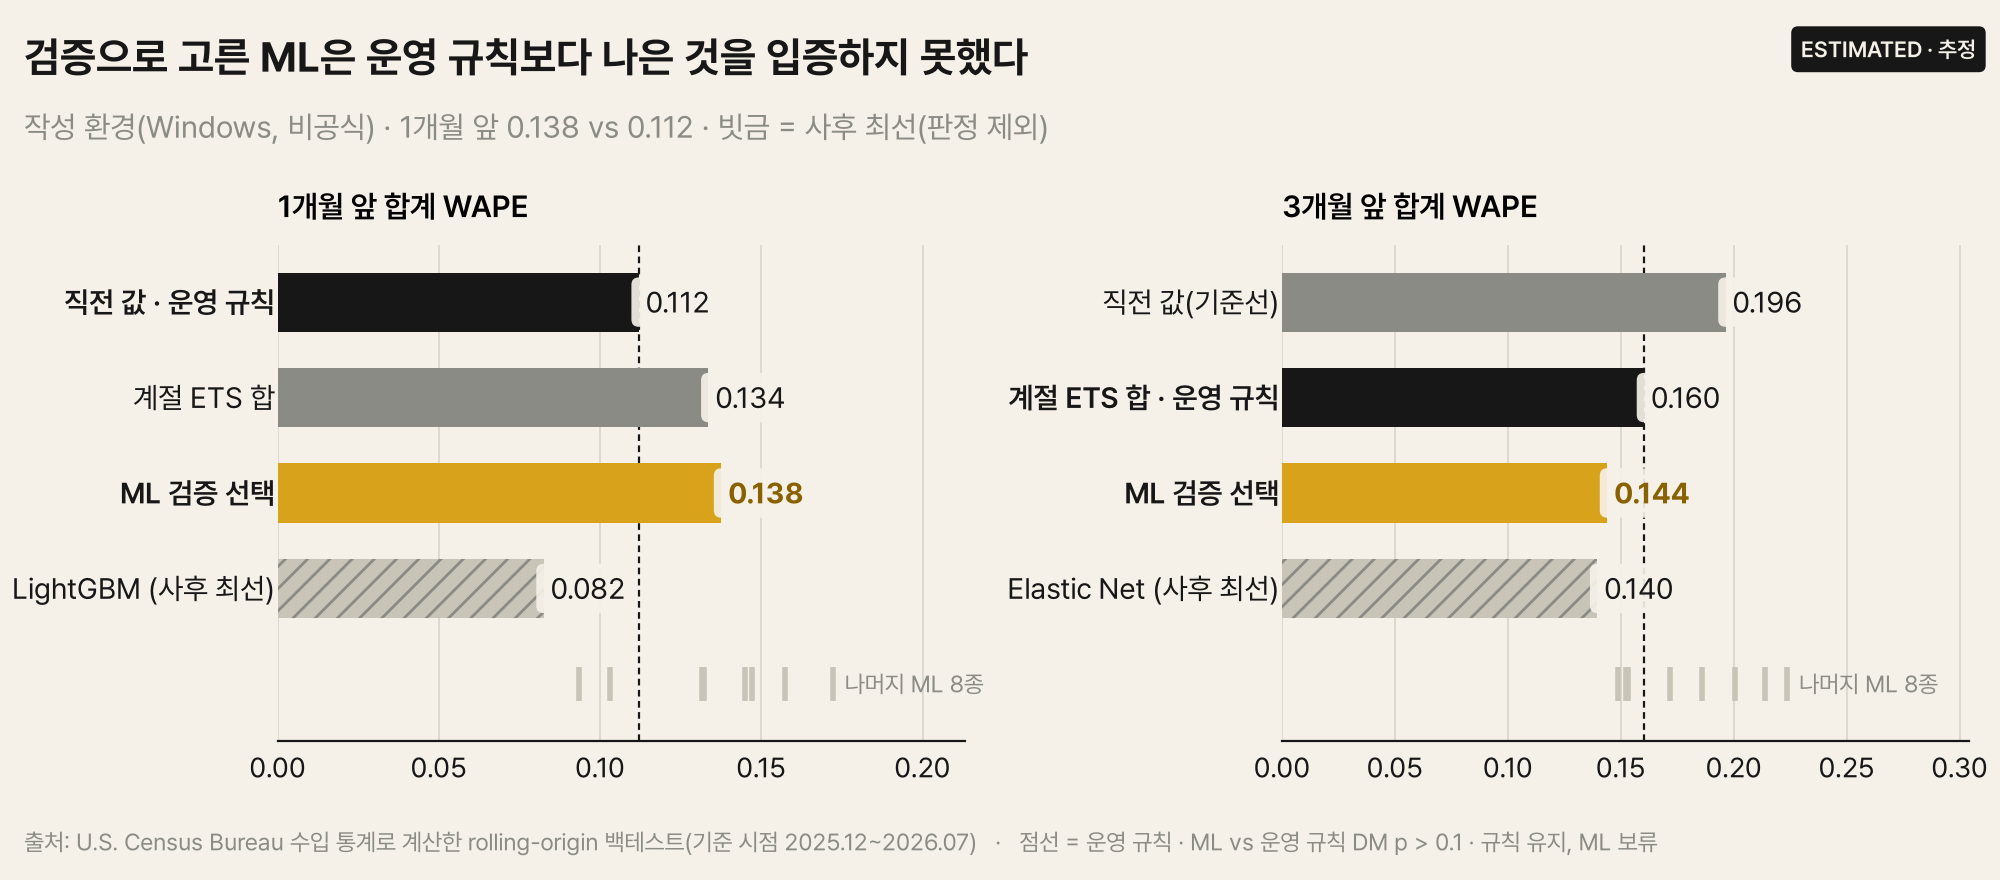

In [7]:
nbviz.show("15_ml_comparison")  # the report figure, drawn from the same backtest table checked in section 10

**발견** (합계 WAPE, 머신러닝은 하위 8개 예측을 더한 bottom-up):

| | 1개월 앞 | 2개월 앞 | 3개월 앞 |
|---|---|---|---|
| 직전 값 | 0.112 | 0.147 | 0.196 |
| 계절 ETS + bottom-up | 0.134 | 0.144 | 0.160 |
| **`ml_selected`(검증 성적으로 자동 선택)** | **0.138** | **0.110** | **0.144** |
| 시험 구간 최선 머신러닝 | LightGBM 0.082 | Gradient Boosting 0.084 | Elastic Net 0.140 |

이 표는 작성 환경(Windows) 결과다. 공식 기준인 Linux 고정 환경에서는 `ml_selected`가 0.109 / 0.126 / 0.144, 계절 ETS 합의 1개월 앞이 0.133이다. 나머지 값은 같다(모델 카드 8절).

- **선택 절차의 정직한 성적(`ml_selected`)은 1개월 앞에서 직전 값과 구분되지 않는다.** 작성 환경에서는 직전 값보다 나쁘고 공식 기준에서는 조금 낮지만, 어느 쪽도 DM p > 0.1이다. 2·3개월 앞에서는 통계 모델 최선보다 낮다.
- **부스팅 3종(LightGBM 0.082, XGBoost 0.093, Gradient Boosting 0.103)은 1개월 앞에서 모두 직전 값을 이겼다.** 하위 8개에서도 XGBoost 0.159, LightGBM 0.161로 직전 값(0.173)보다 낮다.
  하지만 이것은 **9개 모델의 시험 성적을 본 뒤에** 고른 결과다. 모델이 9개면 우연만으로도 몇 개는 기준을 이긴다. 그래서 판정에 쓰지 않고, 2026-09~11 예측을 공개 전에 고정해 검증한다(7절, 사전 등록 변경 기록).
- 거리 기반(kNN)과 신경망(MLP)은 모든 시점에서 직전 값보다 나빴다. 학습 행이 56~200개라 유연한 모델일수록 잡음을 외운다.
- Random Forest·Extra Trees는 1개월 앞에서 나쁘지만 3개월 앞에서는 중간 이상(0.149)이다. 평균을 내는 모델이라 먼 미래의 큰 오차를 줄이는 대신 가까운 미래의 변화를 늦게 따라간다.

### 4.1 검증 구간은 어떤 모델을 골랐나

기준 시점·예측 시점마다 `ml_selected`가 고른 설정과 그 검증 WAPE. 고른 모델이 자주 바뀐다면 검증 구간 3개월로는 모델 간 차이를 안정적으로 구분하지 못한다는 뜻이다.

In [8]:
sel = mlr.selection
picked = sel[sel.model == "ml_selected"]
display(picked.pivot(index="origin", columns="horizon", values="chosen"))
picked.groupby(["horizon", "family"]).size().unstack(fill_value=0)

horizon,1,2,3
origin,,,
2025-12-01,extra_trees[min_samples_leaf=8;level;short],mlp[alpha=0.01;diff;short],lightgbm[num_leaves=8;level;short]
2026-01-01,ridge[alpha=10.0;level;full],extra_trees[min_samples_leaf=8;level;full],xgboost[max_depth=3;level;short]
2026-02-01,xgboost[max_depth=3;diff;short],ridge[alpha=10.0;level;short],xgboost[max_depth=3;level;short]
2026-03-01,lightgbm[num_leaves=8;level;full],random_forest[min_samples_leaf=3;level;full],gradient_boosting[max_depth=3;level;short]
2026-04-01,ridge[alpha=0.1;diff;full],lightgbm[num_leaves=4;level;short],gradient_boosting[max_depth=3;level;short]
2026-05-01,xgboost[max_depth=3;diff;full],xgboost[max_depth=3;level;short],random_forest[min_samples_leaf=8;diff;full]
2026-06-01,gradient_boosting[max_depth=2;diff;full],lightgbm[num_leaves=8;diff;short],NaN
2026-07-01,gradient_boosting[max_depth=3;diff;short],NaN,NaN


family,linear,neural,tree
horizon,,,
1,2,0,6
2,1,1,5
3,0,0,6


In [9]:
# 사후 점검(선택에 쓰지 않음): 검증 성적과 실제 시험 성적은 같은 방향인가
# 기준 시점·예측 시점마다 9개 모델의 검증 WAPE 순위와 시험 WAPE 순위의 상관(Spearman)
test_w = (mlr.forecasts.query("method == 'base' and model != 'ml_selected'")
          .assign(err=lambda d: (d.forecast - d.actual).abs())
          .groupby(["origin", "horizon", "model"]).apply(lambda g: g.err.sum() / g.actual.sum(), include_groups=False).rename("test_wape").reset_index())
rank = sel[sel.model != "ml_selected"].merge(test_w, on=["origin", "horizon", "model"])
rho = rank.groupby(["origin", "horizon"]).apply(lambda g: g.inner_wape.rank().corr(g.test_wape.rank()), include_groups=False).rename("spearman")
rho.groupby("horizon").describe()[["count", "mean", "min", "max"]]

,count,mean,min,max
horizon,,,,
1,8.000,0.019,-0.567,0.717
2,7.000,0.062,-0.467,0.317
3,6.000,0.067,-0.533,0.600


**발견**:
- `ml_selected`가 고른 설정은 **기준 시점마다 바뀌었다**(1개월 앞 8번이 모두 다른 설정, 모델로는 5종). 계열로는 트리가 다수(1개월 앞 6/8, 3개월 앞 6/6)였다.
- 사후 점검: 9개 모델의 **검증 WAPE 순위와 시험 WAPE 순위의 상관이 평균 0.02~0.07**(기준 시점별 −0.57~0.72)로 사실상 0이다.

**판단**: 마지막 3개월(시계열 8개 × 3 = 24개 점)의 검증 성적은 다음 달 성적을 예측하지 못한다. 그래서 "검증에서 1등인 설정"을 매번 고르면 잡음을 따라 모델을 바꾸게 되고,
가장 좋은 계열을 꾸준히 쓰는 것보다 나빠진다. 1개월 앞 `ml_selected`가 직전 값보다 나쁜 이유다.
개선 방향은 검증 구간을 늘리거나(데이터가 쌓여야 가능), 설정 대신 **모델 계열을 고정하고 하이퍼파라미터만 조정**하는 것이다. 어느 쪽이 나은지는 고정 예측의 채점 결과로 판단한다.

### 4.2 무엇이 예측에 쓰였나: 표본 외 순열 중요도

`ml_selected`의 시험 예측에서 특징 하나를 무작위로 섞었을 때 WAPE가 얼마나 나빠지는지(10회 평균). 기준 시점마다 그 시점의 모델로 예측한다. 시험 달은 모두 정책 이후라 '정책 후 여부'는 시험 구간에서 값이 변하지 않아 이 방법으로는 측정할 수 없다.

In [10]:
imp = mlr.importance
imp.pivot(index="feature", columns="horizon", values="wape_rise_mean").sort_values(1, ascending=False)

horizon,1,2,3
feature,,,
lag0,0.533,0.423,0.378
lag1,0.117,0.137,0.102
series,0.069,0.108,0.211
lag_season,0.052,0.047,-0.000
lag2,0.035,0.135,0.167
month_of_year,0.007,0.075,-0.005
post,0.000,0.000,0.000
log_fx,-0.001,0.000,-0.006


**발견** (특징을 섞었을 때 WAPE 상승, 클수록 중요):
- **직전 달 값(lag0)이 압도적**이다(1개월 앞 +0.53, 3개월 앞 +0.38). 머신러닝 모델도 핵심은 '최근 수준'이다. 2절에서 직전 값이 강했던 것과 같은 이유다.
- 예측 거리가 멀어질수록 **시계열 구분(series, 3개월 앞 +0.21)과 2~3개월 전 값(lag2, +0.17)의** 비중이 커진다. 품목·운송수단별 수준 차이와 최근 추세를 함께 쓴다.
- **원/달러는 기여가 없다**(−0.006~0.000). SARIMAX 결과(2절)와 같다. 환율은 단가 분해(02 노트북)에서는 10~23%를 설명하지만, 월 금액 예측에는 정보를 더하지 않는다.
- 작년 같은 달(lag_season)은 1·2개월 앞에서 작은 기여(+0.05)만 있고, 3개월 앞에서는 선택된 6개 설정 중 5개가 이 특징을 쓰지 않아 기여가 0이다.

## 5. 차이가 우연인가: Diebold-Mariano 검정

합계 노드에서 모델 쌍의 절대 오차를 비교한다(HLN 소표본 보정). 기준 시점이 8개(3개월 앞은 6개)뿐이라 검정력이 낮다.
부스팅 모델과 직전 값의 비교는 **결과를 본 뒤 고른 비교**이므로 판정이 아니라 참고로만 읽는다.

In [11]:
def errors(model, method, h, node="total"):
    d = all_bt[(all_bt.model == model) & (all_bt.method == method) & (all_bt.horizon == h) & (all_bt.node == node)].sort_values("origin")
    return (d.forecast - d.actual).to_numpy()

dm = pd.DataFrame([
    {"comparison": "naive vs seasonal_naive", "horizon": 1, **hierarchy.diebold_mariano(errors("naive", "base", 1), errors("seasonal_naive", "base", 1), 1)},
    {"comparison": "ets_seasonal(BU) vs seasonal_naive", "horizon": 3, **hierarchy.diebold_mariano(errors("ets_seasonal", "bottom_up", 3), errors("seasonal_naive", "base", 3), 3)},
    {"comparison": "naive vs ets_seasonal(BU)", "horizon": 1, **hierarchy.diebold_mariano(errors("naive", "base", 1), errors("ets_seasonal", "bottom_up", 1), 1)},
    {"comparison": "ml_selected(BU) vs naive", "horizon": 1, **hierarchy.diebold_mariano(errors("ml_selected", "bottom_up", 1), errors("naive", "base", 1), 1)},
    {"comparison": "ml_selected(BU) vs ets_seasonal(BU)", "horizon": 3, **hierarchy.diebold_mariano(errors("ml_selected", "bottom_up", 3), errors("ets_seasonal", "bottom_up", 3), 3)},
    {"comparison": "[사후] ml_lightgbm(BU) vs naive", "horizon": 1, **hierarchy.diebold_mariano(errors("ml_lightgbm", "bottom_up", 1), errors("naive", "base", 1), 1)},
    {"comparison": "[사후] ml_xgboost(BU) vs naive", "horizon": 1, **hierarchy.diebold_mariano(errors("ml_xgboost", "bottom_up", 1), errors("naive", "base", 1), 1)},
])
dm

,comparison,horizon,dm_stat,p_value,n,lag0_variance
0,naive vs seasonal_naive,1,-1.532,0.169,8,False
1,ets_seasonal(BU) vs seasonal_naive,3,-7.449,0.001,6,False
2,naive vs ets_seasonal(BU),1,-0.651,0.536,8,False
3,ml_selected(BU) vs naive,1,0.689,0.513,8,False
4,ml_selected(BU) vs ets_seasonal(BU),3,-0.173,0.870,6,True
5,[사후] ml_lightgbm(BU) vs naive,1,-1.035,0.335,8,False
6,[사후] ml_xgboost(BU) vs naive,1,-0.742,0.482,8,False


**발견**:
- 직전 값 vs 작년 같은 달(1개월 앞): DM −1.53, **p 0.17**(n = 8). 직전 값의 오차가 평균적으로 작지만, 8개 기준 시점으로는 우연과 구분되지 않는다.
- 계절 ETS(bottom-up) vs 작년 같은 달(3개월 앞): DM −7.45, **p 0.001**(n = 6). 차이가 크고 일관된다. 다만 표본이 6개뿐이고 3개월 앞 오차는 서로 겹쳐 있어 과신하지 않는다.
- 직전 값 vs 계절 ETS(bottom-up)(1개월 앞): p 0.54. 둘 사이의 차이는 구분되지 않는다.
- `ml_selected` vs 직전 값(1개월 앞): DM +0.69, p 0.51(작성 환경. 공식 기준 Linux 고정 환경은 p 0.91). `ml_selected` vs 계절 ETS(3개월 앞): p 0.87(장기 분산이 음수로 추정돼 시차 0 분산으로 대체). **선택 절차는 어느 기준과도 구분되지 않는다.**
- [사후] LightGBM vs 직전 값(1개월 앞): p 0.33, XGBoost: p 0.48. 시험 구간에서 가장 좋았던 모델도 우연과 구분되지 않는다.

**판단**: "작년 같은 달보다 낫다"는 3개월 앞에서만 통계적으로 뒷받침된다. 1개월 앞 모델 순위, 그리고 머신러닝이 통계 모델보다 낫다는 주장은 이 표본으로는 확정하지 않는다.

## 6. 예측 구간: 얼마나 넓게 잡아야 하나

각 기준 시점의 구간은 **다른 기준 시점들의 오차**로만 만든다(자기 오차로 보정하지 않는다). 15개 노드를 모아 80%·95% 구간의 실제 포함률을 본다.

In [12]:
cov = pd.concat([hierarchy.conformal_coverage(bt.query("model == @m and method == @r")).assign(model=m, method=r)
                 for m, r in (("naive", "base"), ("ets_seasonal", "ols"))], ignore_index=True)
cov.assign(width_pct=lambda d: np.expm1(d.mean_width_log / 2)).pivot_table(
    index=["model", "method", "horizon"], columns="level", values=["coverage", "width_pct", "n_invalid"])

coverage       n_invalid       width_pct      
level                          0.800 0.950     0.800 0.950     0.800 0.950
model        method horizon                                               
ets_seasonal ols    1          0.775 0.950     0.000 0.000     0.347 0.689
                    2          0.771 0.933     0.000 0.000     0.369 0.866
                    3          0.756 0.922     1.000 1.000     0.388 0.701
naive        base   1          0.742 0.942     0.000 0.000     0.308 0.695
                    2          0.714 0.933     0.000 0.000     0.416 0.843
                    3          0.767 0.933     0.000 0.000     0.416 0.763

**발견**:
- **95% 구간**: 실제 포함률 92~95%로 명목 수준에 가깝다.
- **80% 구간**: 실제 포함률 71~78%로 **명목보다 낮다**. 구간이 실제 불확실성보다 좁다.
- 구간 폭이 넓다. 80% 구간의 반폭이 약 ±31~42%, 95% 구간은 ±69~87%다. 15개 노드를 모아 보정했으므로, 변동이 큰 작은 노드의 오차가 구간을 넓힌다.

**판단**: 보정용 오차가 기준 시점 7개(자기 시점 제외)뿐이라 구간 추정이 불안정하다. 운영에서는 80% 구간을 그대로 믿기보다
**한 단계 넓혀 쓰고**(예: 90% 구간을 80%처럼 사용), 노드 규모별로 따로 보정하는 것이 안전하다.

## 7. 공개 전에 고정한 예측

2026-11-02에 데이터 공개 전 상태로 2026-09~11 예측 30개를 고정했다([사전 등록](../docs/preregistration.md) 5절). 파일 해시를 확인하고, 공개된 달이 있으면 채점한다.

In [13]:
import hashlib
frozen = sorted((REPO / "reports" / "frozen").glob("forecast_*_frozen_*.csv"))[0]
expected = frozen.with_suffix(".sha256").read_text().split()[0]
print(frozen.name, "| hash ok:", hashlib.sha256(frozen.read_bytes()).hexdigest() == expected)
ff = pd.read_csv(frozen)
published = sorted(m for m in ff.target_month.unique() if pd.Timestamp(m) <= nodes.index[-1])
print("published target months:", published or "none yet (Census latest month: %s)" % nodes.index[-1].strftime("%Y-%m"))
ff[ff.series == "total|value_usd"][["target_month", "forecast_primary", "pi80_low", "pi80_high", "backtest_median_actual_to_forecast"]]

forecast_2026-09_to_2026-11_frozen_2026-11-02.csv | hash ok: True
published target months: none yet (Census latest month: 2026-08)


,target_month,forecast_primary,pi80_low,pi80_high,backtest_median_actual_to_forecast
0,2026-09,233333274,215107602,286048209,1.096
1,2026-10,235110444,231376640,296925117,1.176
2,2026-11,213382609,213382609,284666427,1.203


**발견**: 고정 파일의 해시가 일치한다(공개 후 수정되지 않았음). Census 최신 월이 2026-08이라 **채점할 달이 아직 없다.**
고정 당시 백테스트에서 실제 값은 예측보다 평균 10~20% 높았다(`backtest_median_actual_to_forecast` 1.10~1.20). 성장세가 이어지면 고정 예측은 실제보다 낮게 나올 가능성이 있다.
같은 날 머신러닝 10종의 하위 8개 시계열 예측도 별도 파일(`ml_forecast_…_frozen_2026-11-02.csv`)로 고정했다. 3개월을 합친 하위 8개 WAPE에서 **부스팅 3종이 모두 주 예측보다 낮으면** 4절의 사후 발견을 확인한 것으로 판정한다(사전 등록 변경 기록).
채점은 Census 9월분이 공개되면 `scripts/score_frozen_forecasts.py`로 별도 파일에 추가한다(고정 파일은 수정하지 않는다).

## 8. 결론: 운영 규칙과 근거

| 질문 | 답 | 근거의 강도 |
|---|---|---|
| F1: 무엇으로 예측하나 | 1개월 앞은 **직전 값**(합계 WAPE 0.112), 3개월 앞은 **계절 ETS + bottom-up**(0.160). 작년 같은 달은 모든 수준에서 하위권 | 3개월 앞의 우위는 DM p 0.001(n = 6). 1개월 앞 순위는 확정 불가(p 0.17) |
| F1: 머신러닝 | 9종 76개 설정을 같은 규칙으로 비교. **검증 성적으로 고른 모델은 직전 값과 통계적으로 구분되는 개선을 입증하지 못해 직전 값 기준선을 유지했다(공식 기준 Linux 고정 환경 1개월 0.109 vs 0.112, DM p 0.91. 이 노트북의 작성 환경 값은 0.138)**, 3개월 앞 0.144로 계절 ETS보다 조금 낫다. 부스팅 3종은 1개월 앞에서 직전 값을 이겼지만(0.082~0.103) 사후 비교라 고정 예측으로 검증 중 | 모든 차이가 DM p > 0.1. 검증·시험 순위 상관 ≈ 0 |
| F1: 계층 정합 | bottom-up이 합계 정확도를 일관되게 개선. OLS는 하위 노드를 악화시키고 음수 예측 위험 | 중간 |
| F2: 불확실성 | 95% 구간은 포함률 92~95%로 적절, 80% 구간은 71~78%로 좁음. 반폭 ±31~42% | 보정 표본이 작아 불안정 |
| F3: 고정 예측 | 주 예측과 머신러닝 10종의 해시 확인 완료, 채점 대기(Census 9월분 미공개) | — |
| F4: 한국 통계로 선행 예측 | 이득 없음(0.119 vs 0.112). 양국 기록 비율이 정책 후 이동 중 | 중간 |

### 실무 시사점 (구매·SCM 담당자)
1. **정책 충격 직후에는 '작년 같은 달'을 시장 흐름의 기준으로 쓰지 않는다.** 직전 수준과 계절 모델을 함께 본다.
2. **품목·운송수단별로 따로 예측해 더한다**(bottom-up). 합계를 직접 예측하는 것보다 정확하고, 품목별 계획과 숫자가 맞는다.
3. **복잡한 모델은 검증 구간이 충분할 때 쓴다.** 3개월 검증으로는 모델 순위가 다음 달에 유지되지 않았다. 머신러닝은 고정 예측 채점에서 우위가 확인될 때 도입한다.
4. **예측 구간을 넓게 잡는다.** 80% 구간도 실제로는 75% 안팎만 맞는다. 안전재고 계산에 쓸 때는 한 단계 높은 수준의 구간을 쓴다(06 노트북).

### 한계
- 기준 시점이 8개(3개월 앞 6개)뿐이다. 모델 순위는 데이터가 쌓이면 바뀔 수 있다.
- 머신러닝의 학습 행은 56~200개다. 정책 이전 자료가 대부분이라, 정책 이후 관계를 배울 기회가 적다.
- 미국 측 금액은 04 노트북에서 본 신고 가격 변화의 영향을 받는다. 금액 예측은 '미국 통계에 기록될 금액'의 예측이다.
- SARIMAX의 미래 환율은 마지막 값으로 고정했다. 환율 예측을 넣으면 결과가 달라질 수 있다.

---

## 부록

### A1. 구조 변화 확인

정책 이후 수준이 이동했다면 1년 전 패턴에 기대는 모델이 불리하다. 전년 대비 성장률의 평균이 안정적인지 CUSUM 검정으로 본다.

In [14]:
total = nodes["total"]
pd.DataFrame([hierarchy.cusum_break(np.log(total))])

,cusum_stat,p_value,n
0,0.699,0.713,20


**발견**: CUSUM 통계 0.70, p 0.71(n = 20). 전년 대비 성장률 평균이 불안정하다는 증거는 없다.

**판단**: 이것은 "구조 변화가 없다"는 뜻이 아니다. 관측 20개로는 검정력이 낮다. 01 노트북에서 본 것처럼 변화는 '수준 이동'이다.
수준이 한 번 올라가면 YoY 성장률은 12개월 동안만 높게 나타났다가 원래대로 돌아오므로, 성장률 평균의 안정성 검정으로는 잡기 어렵다.
모델 비교에서 '작년 같은 달'이 불리한지를 직접 보는 것이 더 정확한 확인 방법이다(2절).

### A2. 선행 지표: 한국 수출 통계로 미리 알 수 있나

한국 관세청 통계는 미국 Census보다 약 3주 빨리 나온다. 미국 월 t+1을 '한국 월 t+1 × 최근 3개월 미국/한국 비율'로 예측해 본다.

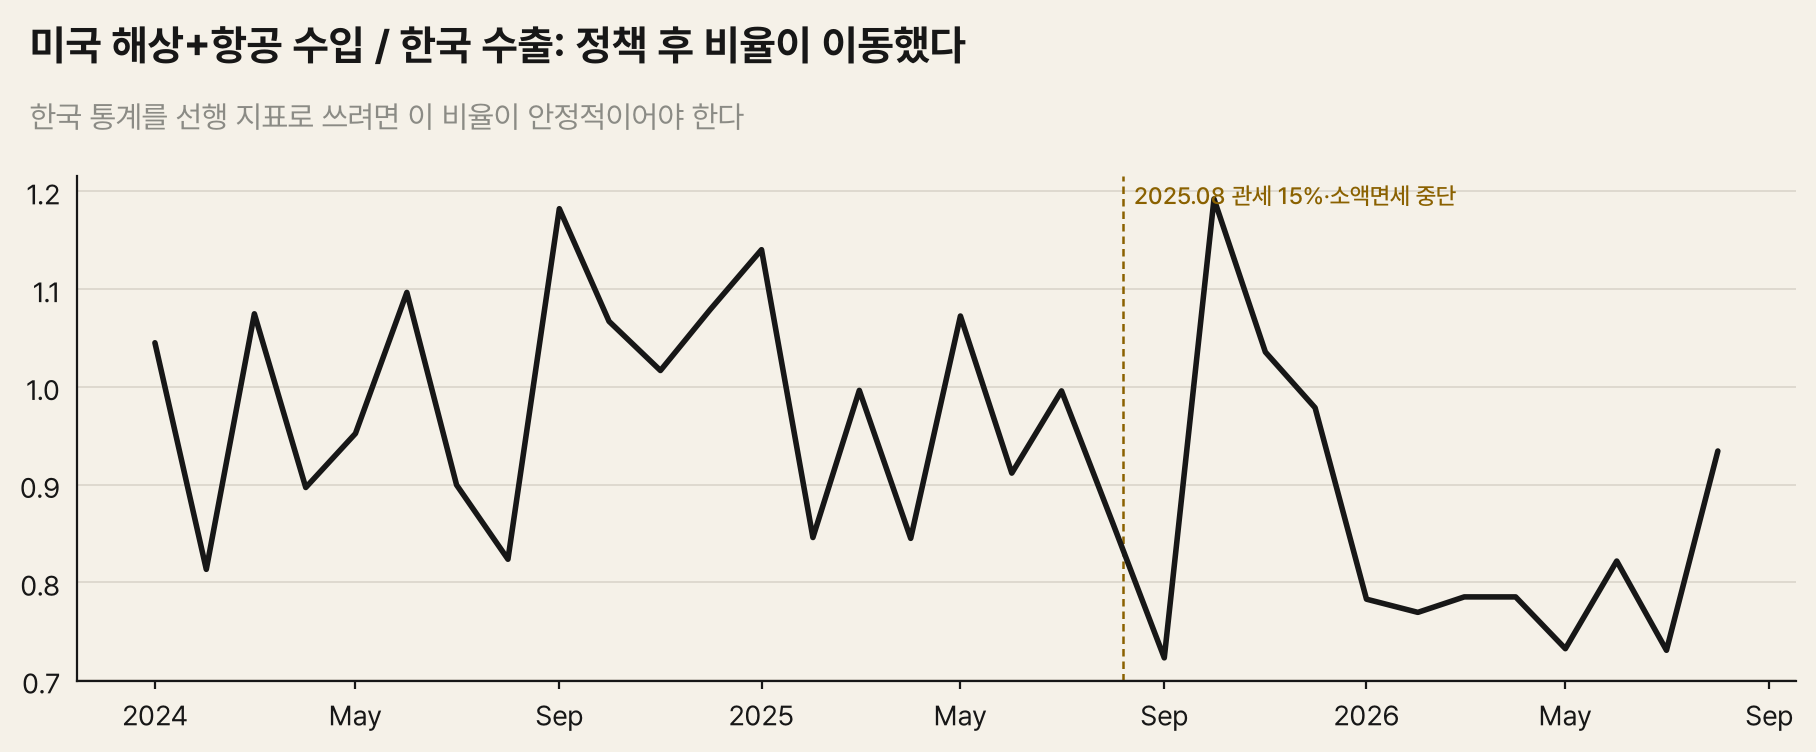

,model,wape
0,naive,0.112
1,nowcast_kr_ratio,0.119
2,seasonal_naive,0.187


In [15]:
mir = warehouse.load("mart_mirror_monthly")
kr_total = mir.assign(month=pd.to_datetime(mir.month)).groupby("month").kr_export_usd.sum()
us_total = nodes["total"]
nbt = hierarchy.nowcast_backtest(us_total, kr_total.reindex(us_total.index), FIRST)
now = hierarchy.wape(nbt, ["model"])
ratio = (us_total / kr_total.reindex(us_total.index))
fig, ax = nbviz.figure(title="미국 해상+항공 수입 / 한국 수출: 정책 후 비율이 이동했다", subtitle="한국 통계를 선행 지표로 쓰려면 이 비율이 안정적이어야 한다")
ax.plot(ratio.index, ratio, color=C["ink"], lw=2)
an.policy_marker(ax)
plt.show()
now

**발견**: 한국 수출 × 최근 3개월 비율로 예측한 1개월 앞 WAPE는 **0.119**로, 직전 값(0.112)보다 나쁘다. 작년 같은 달(0.187)보다는 낫다.
그림에서 미국/한국 비율은 정책 전 1 안팎에서 정책 후 0.75~0.85로 내려갔고, 월별로도 크게 흔들린다.

**판단**: 한국 통계가 3주 빨리 나와도 **선행 지표로서의 이득이 없다.** 04 노트북에서 본 양국 기록 격차가 정책 후 이동하고 있어, 최근 비율로 환산하는 방식이 불안정하기 때문이다.
격차가 안정되면 다시 검토할 가치가 있다.

### A3. 일치 확인

노트북의 백테스트 결과가 `scripts/run_all.py`의 표와 같은지 확인한다.

In [16]:
saved = pd.read_csv(TABLES_DIR / "forecast_hierarchy_wape.csv")
merged = saved.merge(lw_all, on=["model", "method", "horizon", "level"], suffixes=("_saved", "_nb"))
assert len(merged) == len(saved) and np.allclose(merged.wape_saved, merged.wape_nb, atol=1e-12)
saved_now = pd.read_csv(TABLES_DIR / "forecast_nowcast.csv").set_index("model").wape
assert np.allclose(saved_now.sort_index(), now.set_index("model").wape.sort_index(), atol=1e-12)
saved_sel = pd.read_csv(TABLES_DIR / "forecast_ml_selection.csv")
assert saved_sel.chosen.tolist() == sel.chosen.tolist() and np.allclose(saved_sel.inner_wape, sel.inner_wape, atol=1e-12)
saved_imp = pd.read_csv(TABLES_DIR / "forecast_ml_importance.csv")
assert np.allclose(saved_imp.wape_rise_mean, imp.wape_rise_mean, atol=1e-12)
print("notebook backtests match reports/tables: forecast_hierarchy_wape, forecast_nowcast, forecast_ml_selection, forecast_ml_importance")

notebook backtests match reports/tables: forecast_hierarchy_wape, forecast_nowcast, forecast_ml_selection, forecast_ml_importance
